# Titanic Survival Prediction on Real-World Data
Predicting passenger survival using classical machine learning — end-to-end from raw data to Kaggle submission.

|ITEMS|DETAILS|
|---|---|
| **Kaggle score** | 0.758 |
| **Approach** | EDA → feature engineering → sklearn pipeline → 7-model comparison → Bayesian tuning → SHAP |
| **Stack** | pandas, scikit-learn, XGBoost, Optuna, SHAP |
| **Dataset** | [Titanic — Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic) |

---

## 1. Imports

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from xgboost import XGBClassifier

## 2. Load Data
891 labelled training passengers and 418 unlabelled test passengers.

In [3]:
train = pd.read_csv('./datasets/train.csv')
test = pd.read_csv('./datasets/test.csv')
print("Training dataset shape: ", train.shape)
print("Testing dataset shape: ", test.shape)


Training dataset shape:  (891, 12)
Testing dataset shape:  (418, 11)


## 3. Exploratory Data Analysis
Understand survival patterns before writing a single model line.
Key findings: **sex** and **passenger class** are the strongest predictors by far.

In [4]:
print(train['Survived'].value_counts() / train.shape[0] * 100)
train.isna().sum()

Survived
0    61.616162
1    38.383838
Name: count, dtype: float64


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

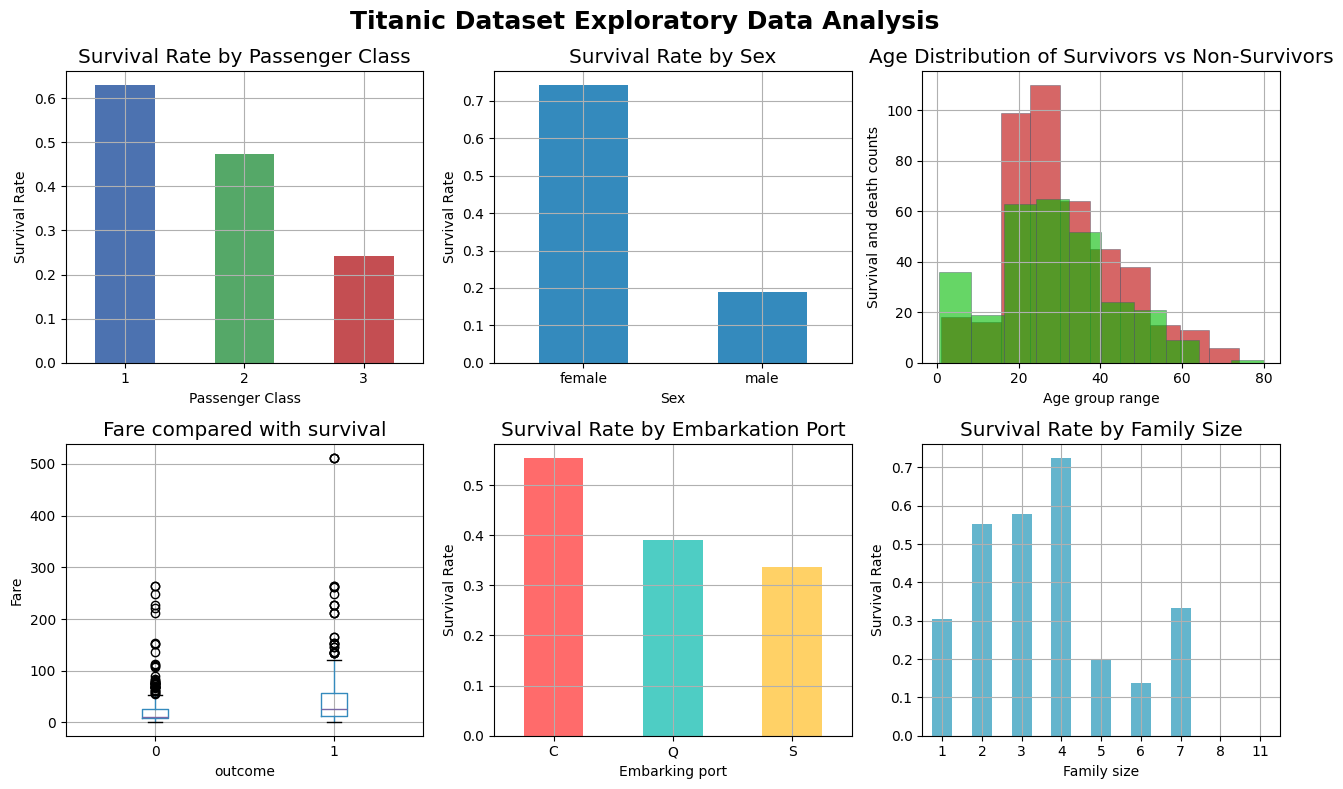

In [5]:
fig, axes = plt.subplots(2, 3, figsize = (13, 8))
plt.style.use('bmh')

train.groupby('Pclass')['Survived'].mean().plot(kind='bar', color=['#4C72B0', '#55A868', '#C44E52'], ax = axes[0,0])
axes[0,0].set_title('Survival Rate by Passenger Class')
axes[0,0].set_xlabel("Passenger Class")
axes[0,0].set_ylabel("Survival Rate")
axes[0,0].tick_params(axis='x', rotation=0)

train.groupby('Sex')['Survived'].mean().plot(kind = 'bar', ax = axes[0,1])
axes[0,1].set_title('Survival Rate by Sex')
axes[0,1].set_xlabel("Sex")
axes[0,1].set_ylabel("Survival Rate")
axes[0,1].tick_params(axis='x', rotation=0)

train[train['Survived'] == 0]['Age'].dropna().hist(alpha = 0.6, color="#bb0000", edgecolor="#4C566A", ax = axes[0,2])
train[train['Survived'] == 1]['Age'].dropna().hist(alpha = 0.6, color="#00bb00", edgecolor="#4C566A", ax = axes[0,2])
axes[0,2].set_title('Age Distribution of Survivors vs Non-Survivors')
axes[0,2].set_xlabel("Age group range")
axes[0,2].set_ylabel("Survival and death counts")

train.boxplot(column = 'Fare', by = 'Survived', ax = axes[1,0])
axes[1,0].set_title('Fare compared with survival')
axes[1,0].set_xlabel("outcome")
axes[1,0].set_ylabel("Fare")

train.groupby('Embarked')['Survived'].mean().plot(kind = 'bar', ax = axes[1,1], color = ['#FF6B6B', '#4ECDC4', '#FFD166'])
axes[1,1].set_title('Survival Rate by Embarkation Port')
axes[1,1].set_xlabel("Embarking port")
axes[1,1].set_ylabel("Survival Rate")
axes[1,1].tick_params(axis='x', rotation=0)


train['FamilySize'] = train['SibSp'] + train['Parch'] + 1
train.groupby('FamilySize')['Survived'].mean().plot(kind='bar', ax = axes[1,2], color = '#64B5CD')
axes[1,2].set_title('Survival Rate by Family Size')
axes[1,2].set_xlabel("Family size")
axes[1,2].set_ylabel("Survival Rate")
axes[1,2].tick_params(axis='x', rotation=0)

fig.suptitle("Titanic Dataset Exploratory Data Analysis", fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Feature Engineering
Create new columns from raw data to capture patterns the model can't learn from the original columns alone.

| Feature | Source | Reasoning |
|---|---|---|
| `Title` | Name | Encodes sex, age range, and class in one variable |
| `FamilySize` | SibSp + Parch | Solo travellers and large groups both survived less |
| `IsAlone` | FamilySize | Binary: travelling solo or not |
| `FamilySizeType` | FamilySize | Alone / small / large buckets |
| `AgeGroup` | Age | Captures non-linear patterns at age extremes |
| `Embarked` | Embarked | 2 missing values filled with most common port |

In [6]:
def feature_engineer(df):
    df = df.copy()

    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
    df['FamilySizeType'] = pd.cut(df['FamilySize'], bins = [0,1,4,11], labels = ['alone', 'small', 'large'])

    df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

    df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
    df['Title'] = df['Title'].replace(['Lady','Countess','Capt','Col','Don','Dr','Major','Rev','Sir','Jonkheer','Dona'],'Rare')
    df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})

    age_median = df.groupby(['Title', 'Pclass'])['Age'].transform('median')
    df['Age'] = df['Age'].fillna(age_median)
    df['Age'] = df['Age'].fillna(df['Age'].median())
    df['AgeGroup'] = pd.cut(df['Age'], bins=[0, 9, 18, 35, 60, 100], labels=['child','teen','adult','middle','senior'], include_lowest = True)

    df['Fare'] = df['Fare'].fillna(df['Fare'].median())

    df.columns
    return df

train = feature_engineer(train)
test = feature_engineer(test)

## 5. Preprocessing Pipeline
Numeric: median imputation → standard scaling.  
Categorical: most-frequent imputation → one-hot encoding.  
Wrapped in a `Pipeline` so preprocessing is fit only on training folds, preventing data leakage.

In [7]:
numerical_features = ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
categorical_features = ['Pclass', 'Sex', 'Embarked', 'FamilySizeType', 'Title', 'AgeGroup']

x_train = train[numerical_features + categorical_features]
y_train = train['Survived']
x_test = test[numerical_features + categorical_features]

In [8]:
numerical_transformer = Pipeline(steps = [
    ('imputer', SimpleImputer(strategy = 'median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps = [
    ('imputer', SimpleImputer(strategy = 'most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers = [
    ('numerical', numerical_transformer, numerical_features),
    ('categorical', categorical_transformer, categorical_features)
])

## 6. Model Comparison
7 classical ML algorithms evaluated on identical 5-fold stratified folds.  
Every model gets the same preprocessor and the same splits — a fair comparison.

In [9]:
models = {
    'Logistic Regression' : LogisticRegression(max_iter = 2000, random_state = 37),
    'Decision Tree' : DecisionTreeClassifier(max_depth = 5, random_state = 37),
    'Random Forest' : RandomForestClassifier(n_estimators = 200, max_depth = 5, random_state = 37),
    'SVM' : SVC(kernel = 'rbf', C = 1, probability = True, random_state = 37),
    'KNN' : KNeighborsClassifier(n_neighbors = 7),
    'Gradient Boosting' : GradientBoostingClassifier(n_estimators = 200, learning_rate = 0.05, random_state = 37),
    'XGBoost' : XGBClassifier(n_estimators = 200, learning_rate = 0.05, eval_matrix = 'logloss', verbosity = 0, random_state = 37)
}

results = {}
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 37)

for name, model in models.items():
    modelpipe = Pipeline(steps = [
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    scores = cross_val_score(modelpipe, x_train, y_train, cv = cv, scoring = 'accuracy', n_jobs = -1)
    results[name] = scores
    print(f"{name} : {scores.mean() * 100:.3f}%")

Logistic Regression : 82.714%
Decision Tree : 81.371%
Random Forest : 82.938%
SVM : 83.162%
KNN : 79.687%
Gradient Boosting : 81.930%
XGBoost : 83.501%


C:\Users\Kushagra\AppData\Local\Temp\ipykernel_52992\1580782031.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([results[m] for m in results], labels=results.keys())


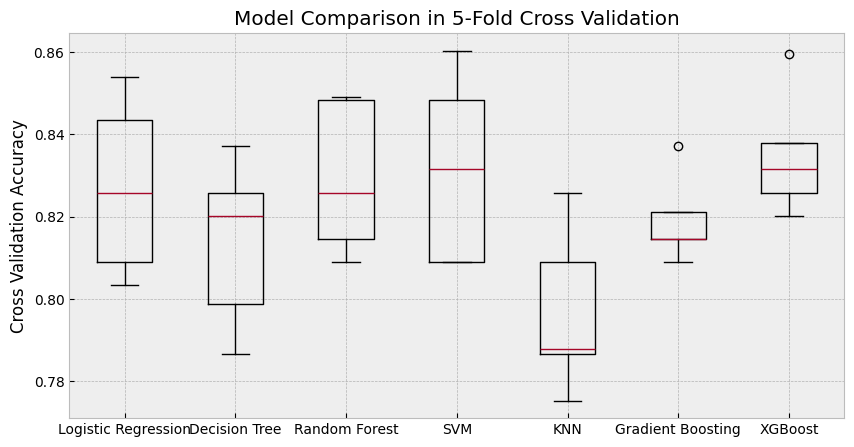

In [10]:
plt.figure(figsize=(10, 5))
plt.boxplot([results[m] for m in results], labels=results.keys())
plt.ylabel('Cross Validation Accuracy')
plt.title('Model Comparison in 5-Fold Cross Validation')
plt.savefig('model_CVcomparison.png')
plt.show()

## 7. Hyperparameter Tuning
Bayesian search over XGBoost hyperparameters using Optuna's TPE sampler.  
Each of the 50 trials runs a full 5-fold cross-validation internally (250 models total).

In [11]:
def to_be_optimized(trial):
    params = {
        'n_estimators' : trial.suggest_int('n_estimators', 100, 500),
        'max_depth' : trial.suggest_int('max_depth', 4, 9),
        'learning_rate' : trial.suggest_float('learning_rate', 0.001, 0.3, log = True),
        'subsample' : trial.suggest_float('subsample', 0.6, 1),
        'colsample_bytree' : trial.suggest_float('colsample_bytree', 0.6, 1),
        'min_child_weight' : trial.suggest_int('min_child_weight', 1, 10),
        'gamma' : trial.suggest_float('gamma', 0, 5),
        'eval_metric' : 'logloss',
        'random_state' : 37,
        'verbosity' : 0
    }

    model = Pipeline(steps = [
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(**params))
    ])

    score = cross_val_score(model, x_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1).mean()

    return score

sampler = optuna.samplers.TPESampler(seed = 37)
study = optuna.create_study(direction = 'maximize', sampler = sampler)
study.optimize(to_be_optimized, n_trials = 50)

print('Best CV accuracy : ', study.best_value)
print('Associated params : ', study.best_params)

[I 2026-07-07 10:30:33,266] A new study created in memory with name: no-name-536cb4be-6c6d-47ac-97f4-05f19903eaf9
[I 2026-07-07 10:30:33,633] Trial 0 finished with value: 0.8125855250768941 and parameters: {'n_estimators': 478, 'max_depth': 6, 'learning_rate': 0.0030031475060741286, 'subsample': 0.8327579507519968, 'colsample_bytree': 0.8480336840694509, 'min_child_weight': 7, 'gamma': 0.5171877750999904}. Best is trial 0 with value: 0.8125855250768941.
[I 2026-07-07 10:30:33,848] Trial 1 finished with value: 0.8125729709371665 and parameters: {'n_estimators': 398, 'max_depth': 5, 'learning_rate': 0.07350621468109604, 'subsample': 0.9170822518282864, 'colsample_bytree': 0.8509602385117438, 'min_child_weight': 5, 'gamma': 4.817326762037329}. Best is trial 0 with value: 0.8125855250768941.
[I 2026-07-07 10:30:34,117] Trial 2 finished with value: 0.8294017952419811 and parameters: {'n_estimators': 459, 'max_depth': 5, 'learning_rate': 0.02993940869788679, 'subsample': 0.8293507781924053, 

Best CV accuracy :  0.8439708743958321
Associated params :  {'n_estimators': 225, 'max_depth': 9, 'learning_rate': 0.1831293094286831, 'subsample': 0.6957402895844126, 'colsample_bytree': 0.7957627217567483, 'min_child_weight': 7, 'gamma': 0.42124358485345637}


## 8. Final Model & Submission
Train on all 891 passengers using Optuna's best parameters.  
Predict on 418 test passengers and export `submissions.csv` for Kaggle upload.

In [12]:
best_params = study.best_params
best_params.update({'eval_metric' : 'logloss', 'random_state' : 37, 'verbosity' : 0})

final_model = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(**best_params))
])

final_model.fit(x_train, y_train)
print(f"Final Training Accuracy : {final_model.score(x_train, y_train) * 100:.3f}%")
predictions = final_model.predict(x_test)
submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived': predictions
})

submission.to_csv('submissions.csv', index = False)
print("Final predictions made and submission file created")

Final Training Accuracy : 89.450%
Final predictions made and submission file created


## 9. SHAP Explainability
Understand *why* the model makes each prediction, not just what it predicts.

- **Bar chart** — which features matter most globally
- **Beeswarm** — direction and magnitude of each feature's effect across all passengers  
- **Force plot** — why the model made a specific prediction for one passenger

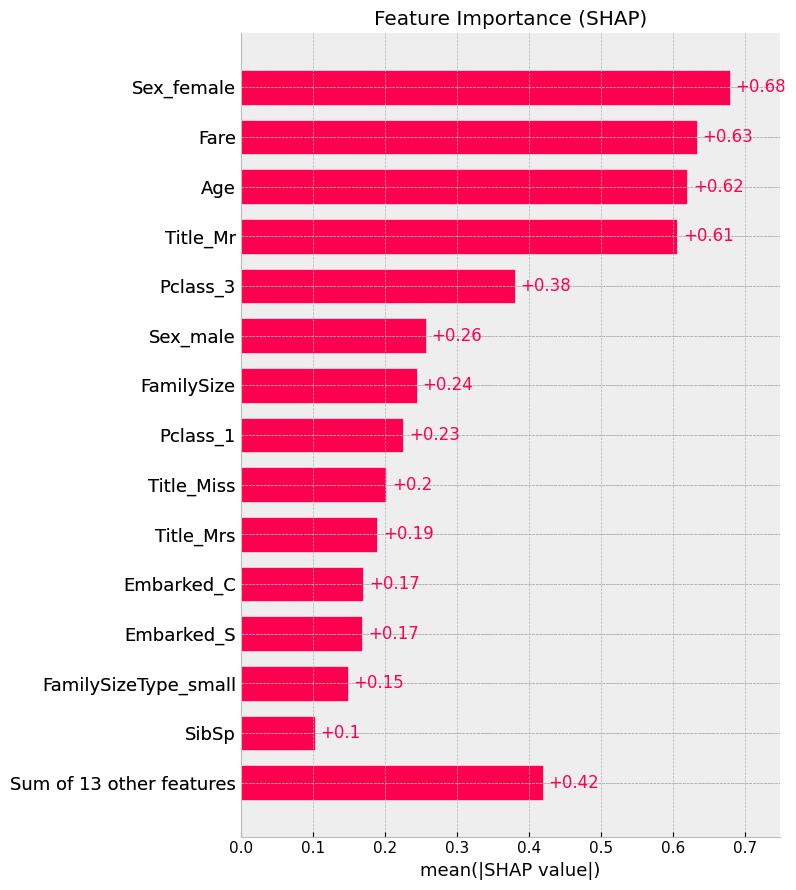

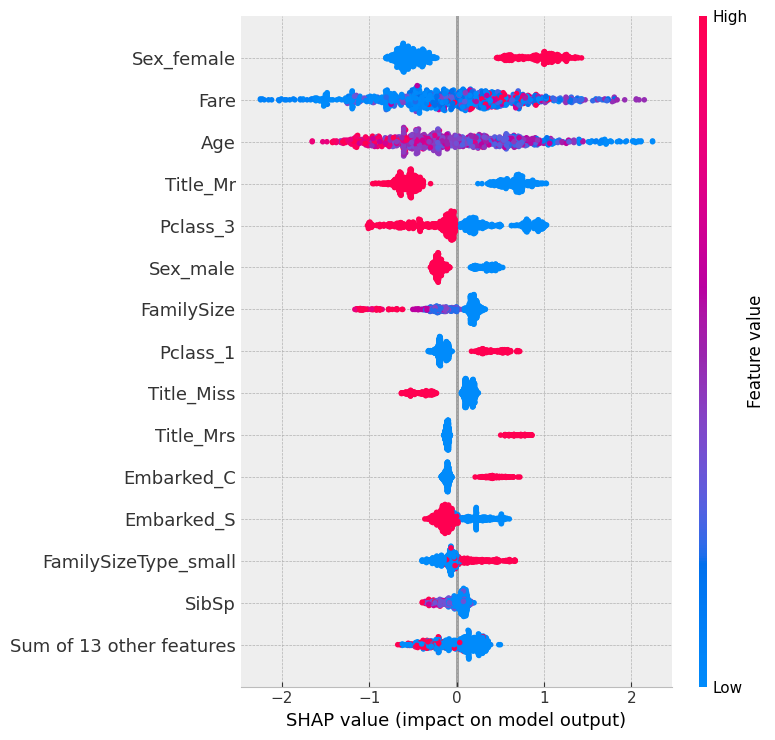

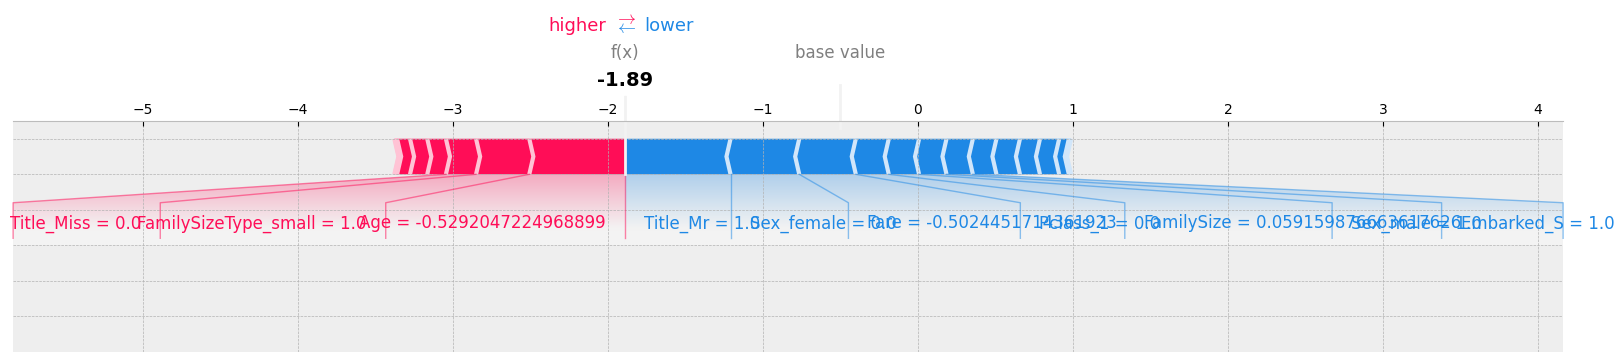

In [13]:
import shap

import shap.explainers._tree as _shap_tree
_orig_float = float
def _safe_float(x):
    if isinstance(x, str) and x.strip().startswith('['):
        return _orig_float(x.strip('[]').split(',')[0])
    if isinstance(x, (list, tuple)):
        return _orig_float(x[0])
    return _orig_float(x)
_shap_tree.float = _safe_float

fitted_preprocessor = final_model.named_steps['preprocessor']
fitted_classifier   = final_model.named_steps['classifier']

X_train_processed = fitted_preprocessor.transform(x_train)

num_feature_names = numerical_features
cat_feature_names = fitted_preprocessor.named_transformers_['categorical'] \
                       .named_steps['encoder'].get_feature_names_out(categorical_features).tolist()
all_feature_names = num_feature_names + cat_feature_names

X_train_processed = pd.DataFrame(X_train_processed, columns=all_feature_names)

explainer = shap.TreeExplainer(fitted_classifier, feature_perturbation='tree_path_dependent')
explanation = explainer(X_train_processed, check_additivity=False)

# Plot 1: Feature importance (global)
plt.figure(figsize=(10, 8))
shap.plots.bar(explanation, max_display=15, show=False)
plt.title('Feature Importance (SHAP)')
plt.tight_layout()
plt.savefig('shap_importance.png', dpi=150)
plt.show()

# Plot 2: Beeswarm
plt.figure(figsize=(10, 8))
shap.plots.beeswarm(explanation, max_display=15, show=False)
plt.tight_layout()
plt.savefig('shap_beeswarm.png', dpi=150)
plt.show()

# Plot 3: Single passenger explanation
shap.force_plot(explanation[0].base_values,
                 explanation[0].values,
                 X_train_processed.iloc[0],
                 matplotlib=True, show=False)
plt.savefig('shap_passenger.png', dpi=150)
plt.show()